## Soveltava matematiikka ja fysiikka ohjelmoinnissa, harjoitukset 9.11.2026

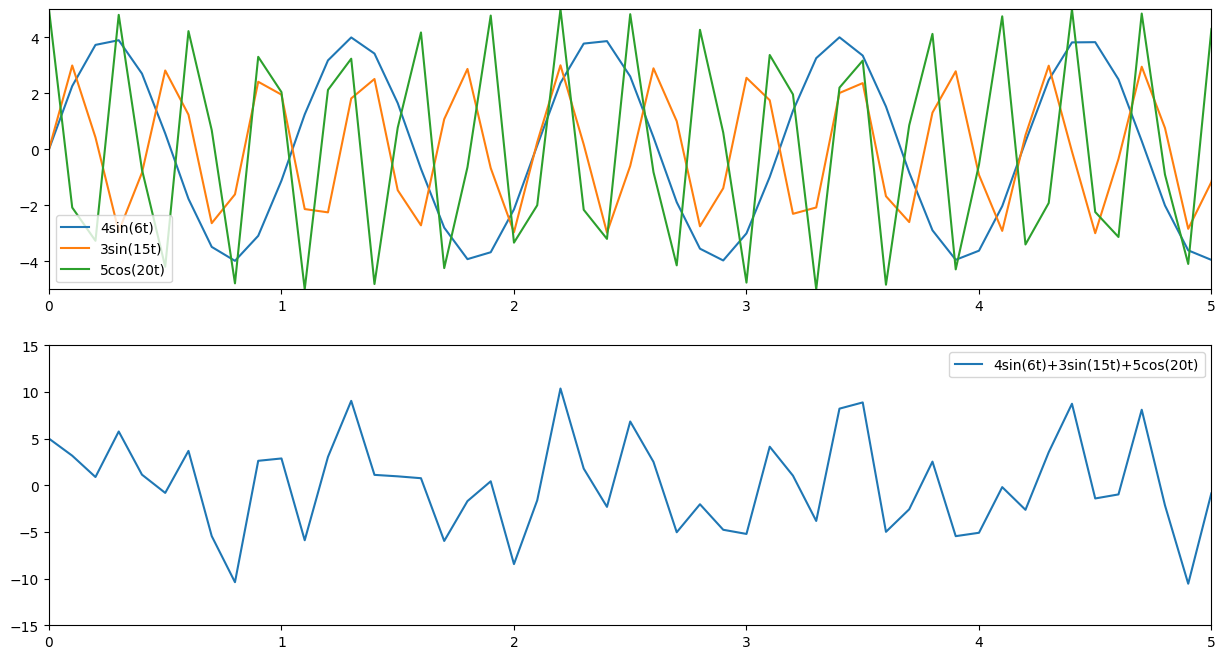

In [11]:
# Tehtävä 12
# Muodosta signaali

# s(t)=4sin(6t)+3sin(15t)+5cos(20t)
# näytteenottovälillä 0,1 s aikavälillä 0≤t<100 s.

# a) Piirrä osasignaalit ja niiden summa. Rajaa aika-akselia tarvittaessa.

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

dt = 0.1 #Näytteenottoväli
t = np.arange(0,100,dt) #Aika

s1 = 4*np.sin(6*t)
s2 = 3*np.sin(15*t)
s3 = 5*np.cos(20*t)
s = s1 + s2 + s3

#Piirretään kuva osasignaaleista s1, s2 ja s3, sekä summasignaalista
plt.figure(figsize = (15,8))
plt.subplot(2,1,1)
plt.plot(t,s1,label = '4sin(6t)')
plt.plot(t,s2,label = '3sin(15t)')
plt.plot(t,s3,label = '5cos(20t)')
plt.axis([0,5,-5,5])
plt.legend()
plt.subplot(2,1,2)
plt.plot(t,s, label = '4sin(6t)+3sin(15t)+5cos(20t)')
plt.legend()
plt.axis([0,5,-15,15])
plt.show()

#Huomataan, että summasignaalista on hyvin vaikeaa suoraan nähdä, mitä taajuuksia siinä on mukana. 

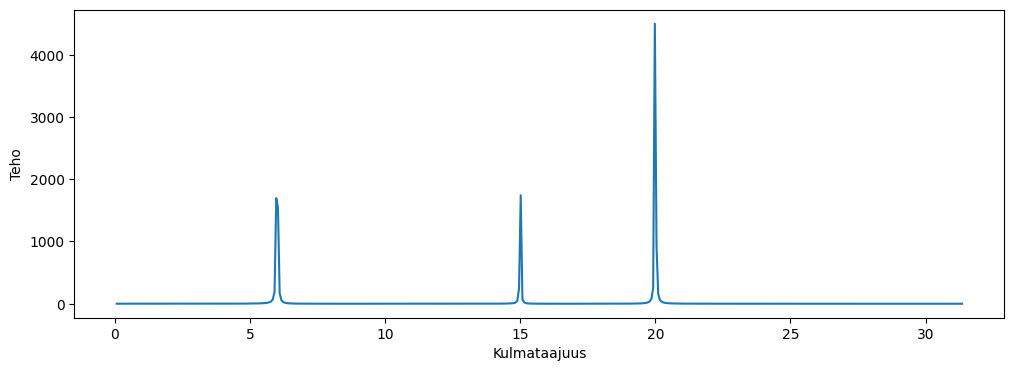

In [ ]:

#Dirichlet’n Fourier-lause: Jaksollinen signaali (funktio) voidaan esittää sini-ja kosimuotoisten signaalien (funktioiden summana)
#Eli käytännössä voidaan selvittää, miten summasignaali on rakentunut, vaikka meillä olisi tiedossa ainoastaan havaittu summasignaali. 

# b) Laske summan Fourier-muunnos FFT-algoritmilla ja sen tehospektri.
# Syntakseja on monenlaisia, mutta yritän tässä käyttää mahdollisimman havainnollista.
N = len(s) #Datapisteiden määrä
fourier = np.fft.fft(s,N) #Fourier-muunnos
#Kuvaa signaalin s taajuusavaruudessa. Käytännössä sisältää tarkan tiedon siitä, millaisista sini-ja kosifunktiosta s rakentuu. 

#Tehospektri kertoo, kuinka suuri on minkäkin signaalissa esiintyvän taajuuden teho. Se ei erottele sini- ja kosinikomponentteja
psd = fourier*np.conj(fourier)/N #Tehospektri

# c) Muodosta taajuusakseli hertseinä ja tunnista spektrin huiput.
freq = np.fft.fftfreq(N,dt) #Taajuudet, joita datasta voidaan havaita

#Rajataan pois negatiiviset taajuudet
#Muistetaan taajuuden ja kulmtaajuuden välinen yhteys: omega = 2*pi*f
#Muistetaan, että sini- ja kosifunktiot ovat muotoa sin(omega*t) ja cos(omega*t)
L = np.arange(1,np.floor(N/2),dtype = 'int')
plt.figure(figsize=(12,4))
#plt.plot(freq[L],psd[L].real)
#plt.xlabel('Taajuus')
plt.plot(2*np.pi*freq[L],psd[L].real)
plt.xlabel('Kulmataajuus')
plt.ylabel('Teho')
plt.show()

# d) Vertaa huippujen (kulma)taajuuksia alkuperäisten funktioiden kulmataajuuksiin.
#s(t)=4sin(6t)+3sin(15t)+5cos(20t)
# Huomataan, että alkuperäisen signaalin (kulma)taajuudet havaitaan selvästi piikkeinä tehospektrissä.

c:\Users\ilpovirt\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\ilpovirt\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


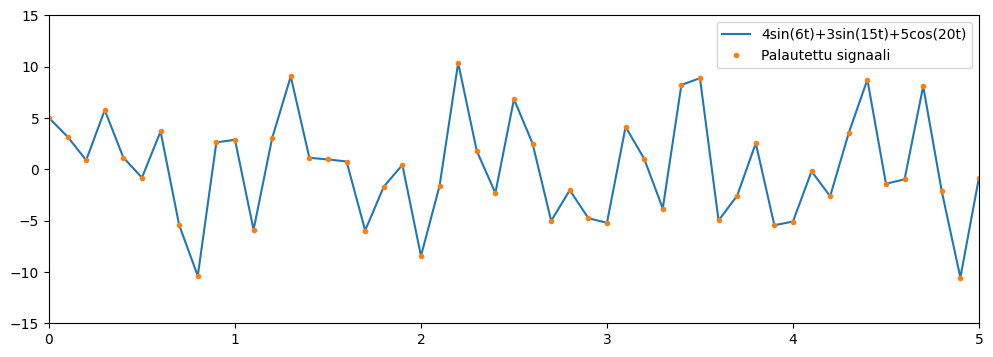

In [28]:
# e) Palauta signaali käänteismuunnoksella ja vertaa sitä alkuperäiseen.
s_pal = np.fft.ifft(fourier,N)

plt.figure(figsize=(12,4))
plt.plot(t,s, label = '4sin(6t)+3sin(15t)+5cos(20t)')
plt.plot(t,s_pal, ' .' ,label = 'Palautettu signaali')
plt.legend()
plt.axis([0,5,-15,15])
plt.show()

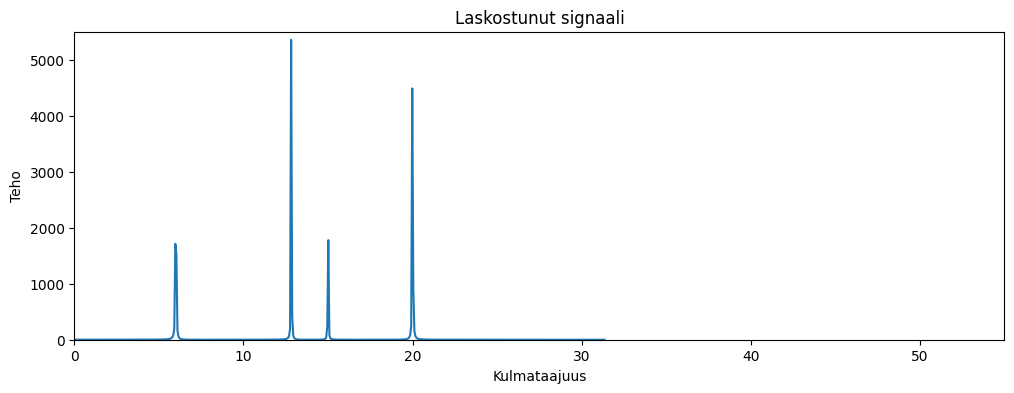

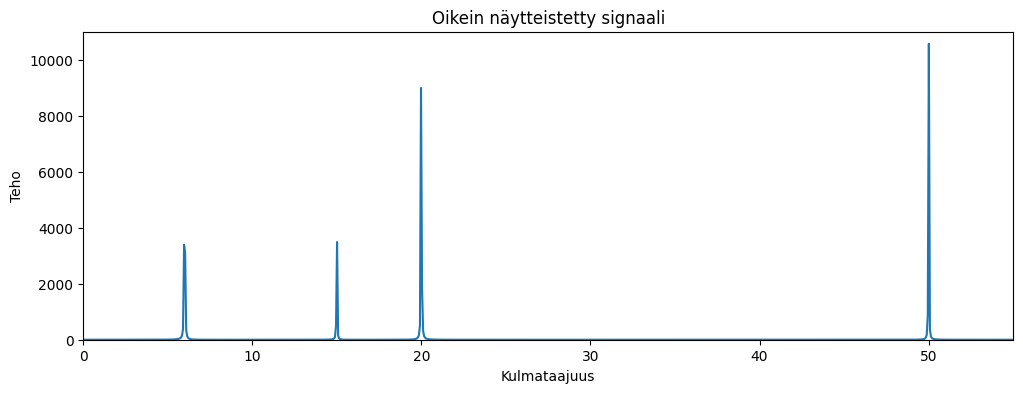

In [38]:
# Tehtävä 13
# Lisää tehtävän 12 signaaliin 5cos(50t).
# a) Tutki muutosta tehospektrissä käyttäen edelleen näytteenottoväliä 0,1 s.
# b) Selitä, miksi uusi huippu ei näy odotetulla taajuudella.
# c) Valitse riittävä näytteenottotaajuus ja tarkista tulos muodostamalla signaali ja laskemalla Fourier-muunnos uudelleen.

dt = 0.1
t = np.arange(0,100,dt)
s = 4*np.sin(6*t) + 3*np.sin(15*t) + 5*np.cos(20*t) + 5*np.cos(50*t)

#Fourier-muunnos ja tehospektri
N = len(s)
fourier = np.fft.fft(s,N)
psd = fourier*np.conj(fourier)/N
freq = np.fft.fftfreq(N,dt)
L = np.arange(1,np.floor(N/2),dtype = 'int')

plt.figure(figsize=(12,4))
plt.plot(2*np.pi*freq[L],psd[L].real)
plt.axis([0,55,0,5500])
plt.xlabel('Kulmataajuus')
plt.ylabel('Teho')
plt.title('Laskostunut signaali')
plt.show()

#Huomataan, että piikkiä ei näy 50 kulmataajuudella, vaan virheellinen piikki 13 paikkeilla. 
#Tämä on laskostumisen syytä:
#Näytteenottotaajuus on 10Hz, joten suurin taajuus joka voidaan havaita on 5Hz (Nyqvistin taajuus), jota vastaa kulmataajuus 5*2*pi = 31.4
#Nyqvistin taajuutta suuremmat taajuudet tulee suodattaa signaalista ennen näytteistystä. 
#Näytteenottotaajuutta voidaan nosta (jos mahdollista. )

dt = 0.05
t = np.arange(0,100,dt)
s = 4*np.sin(6*t) + 3*np.sin(15*t) + 5*np.cos(20*t) + 5*np.cos(50*t)

#Fourier-muunnos ja tehospektri
N = len(s)
fourier = np.fft.fft(s,N)
psd = fourier*np.conj(fourier)/N
freq = np.fft.fftfreq(N,dt)
L = np.arange(1,np.floor(N/2),dtype = 'int')

plt.figure(figsize=(12,4))
plt.plot(2*np.pi*freq[L],psd[L].real)
plt.axis([0,55,0,11000])
plt.xlabel('Kulmataajuus')
plt.ylabel('Teho')
plt.title('Oikein näytteistetty signaali')
plt.show()

## Soveltava matematiikka ja fysiikka ohjelmoinnissa, harjoitukset 18.11.2026

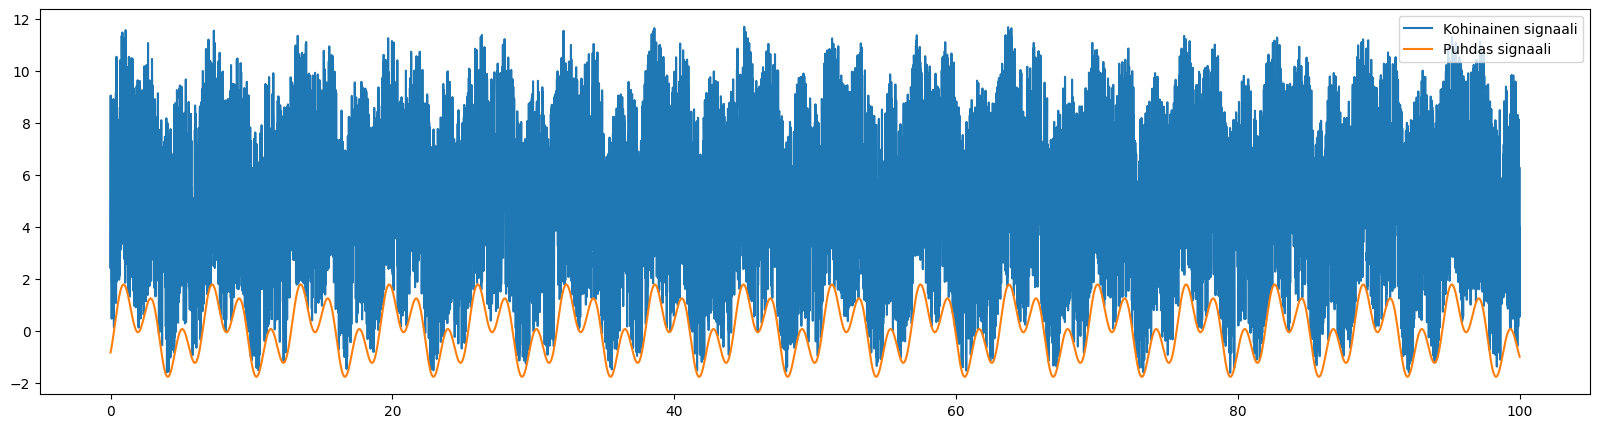

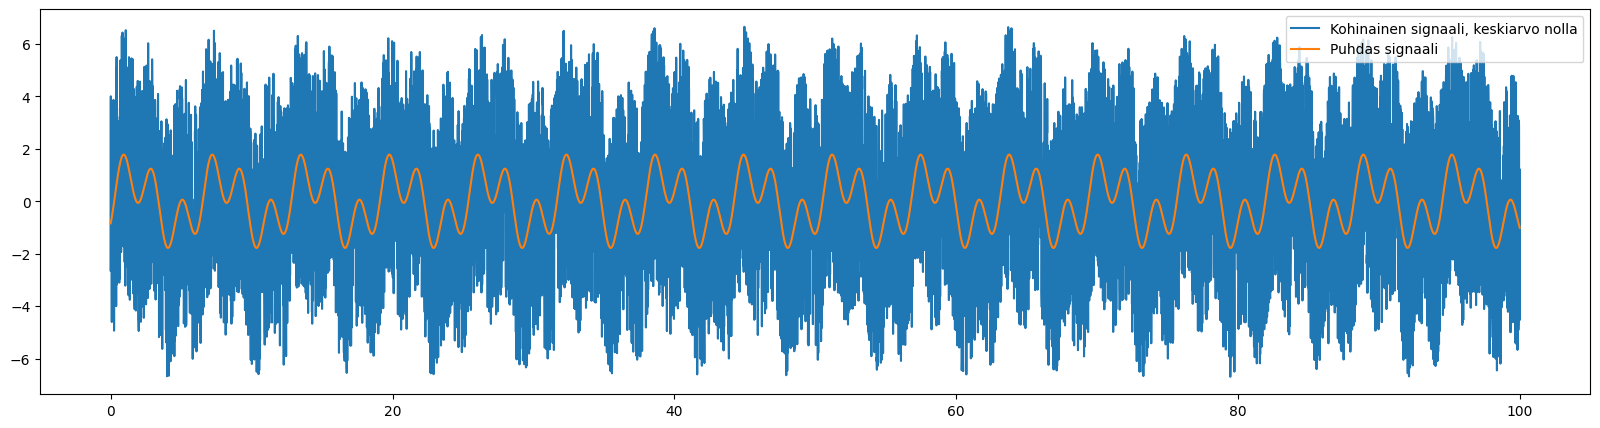

In [ ]:
# Tehtävä 14
# Muodosta kohinainen signaali seuraavasti:
import numpy as np
rng = np.random.default_rng(8)
t = np.arange(0, 100, 0.01)
clean_signal = np.sin(t) + np.sin(3*t - 1)
noisy_signal = clean_signal + 10*rng.random(len(t))

# a) Piirrä puhdas ja kohinainen signaali samaan kuvaan.
plt.figure(figsize=(20,5))
plt.plot(t,noisy_signal,label = "Kohinainen signaali")
plt.plot(t,clean_signal,label = 'Puhdas signaali')
plt.legend()
plt.show()


# b) Poista kohinaisen signaalin keskiarvo, laske Fourier-muunnos ja tunnista merkittävät taajuuskomponentit.
## Olisi ollut parempi aloittaa signaalista zero_mean_signal, koska se on realistisempi tapaus. 
zero_mean_signal = noisy_signal - np.mean(noisy_signal)
plt.figure(figsize=(20,5))
plt.plot(t,zero_mean_signal,label = "Kohinainen signaali, keskiarvo nolla")
plt.plot(t,clean_signal,label = 'Puhdas signaali')
plt.legend()
plt.show()

# c) Suodata kohinaa Fourier-muunnoksen avulla ja palauta signaali käänteismuunnoksella. Vertaa tulosta tunnettuun puhtaaseen signaaliin.

## Ekstra: tehdään jos ehditään
# d) Toista analyysi kirjan mukana toimitettavalle synteettiselle tiedostolle signal_to_be_cleaned.csv. 
# Käytä näytteenottoväliä 1 s. Tunnista kolme hallitsevaa positiivista taajuutta ja piirrä puhdistettu signaali.



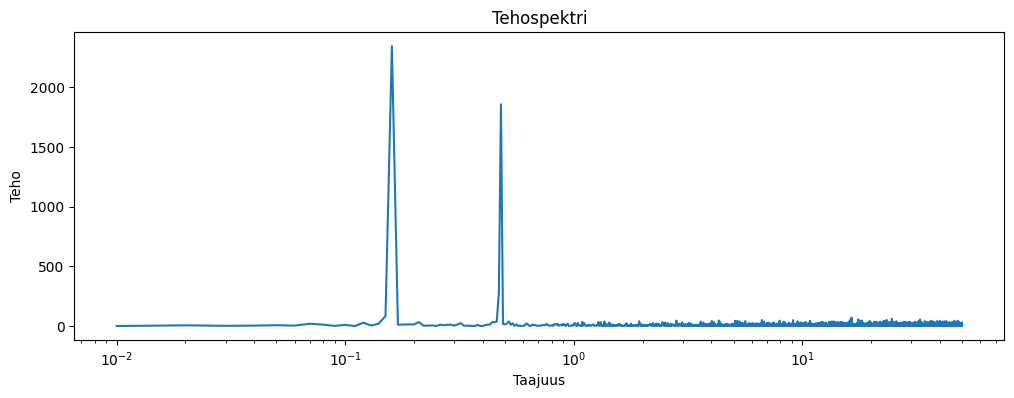

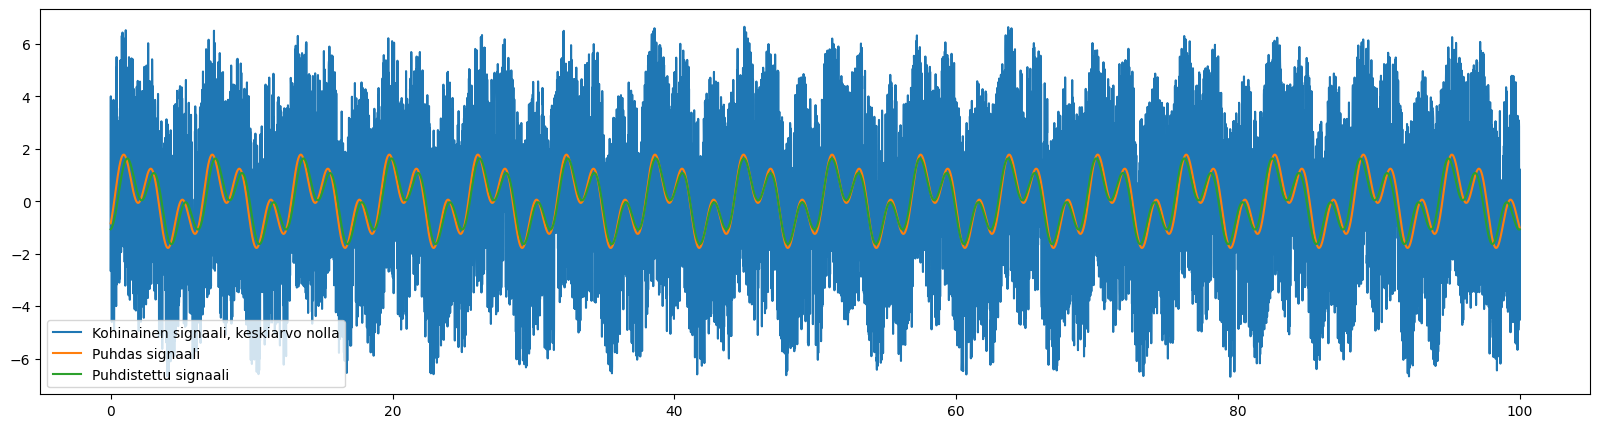

In [ ]:
# b) Poista kohinaisen signaalin keskiarvo, laske Fourier-muunnos ja tunnista merkittävät taajuuskomponentit.

dt = 0.01
#Fourier-muunnos ja tehospektri
N = len(zero_mean_signal)
fourier = np.fft.fft(zero_mean_signal,N)
psd = fourier*np.conj(fourier)/N
freq = np.fft.fftfreq(N,dt)
L = np.arange(1,np.floor(N/2),dtype = 'int')

plt.figure(figsize=(12,4))
plt.plot(freq[L],psd[L].real)
#plt.axis([0,1,0,2500])
plt.xscale('log')
plt.xlabel('Taajuus')
plt.ylabel('Teho')
plt.title('Tehospektri')
plt.show()

#Huomataan, että kaksi taajuuspiikkiä dominoi tehospektriä ja niiden ulkopuolella kaikki on kohinaa. 

# c) Suodata kohinaa Fourier-muunnoksen avulla ja palauta signaali käänteismuunnoksella. Vertaa tulosta tunnettuun puhtaaseen signaaliin.

#Nyt voidaan rajata, että säilytettävän taajuuden tehon tulee olla esim. yli 1000. Tällöin kaikki kohina rajautuu pois. 
fourier_clean = fourier.copy()
fourier_clean[psd.real < 1000] = 0 #Rajataan fourier-muunnoksesta pois taajuudet, joiden teho oln alle 1000
signal_cleaned = np.fft.ifft(fourier_clean) #Palautetaan signaali käänteissmuunnoksella

plt.figure(figsize=(20,5))
plt.plot(t,zero_mean_signal,label = "Kohinainen signaali, keskiarvo nolla")
plt.plot(t,clean_signal,label = 'Puhdas signaali')
plt.plot(t,signal_cleaned.real,label = 'Puhdistettu signaali')
plt.legend()
plt.show()

#Huomio 1: Signaalin puhdistus toimii hyvin, puhdistettu signaali on lähelllä alkuperäistä puhdasta signaalia
#Huomio 2: Puhdistus ei toimi täydellisesti. Suurin syy on signaalin rajallinen pituus. 

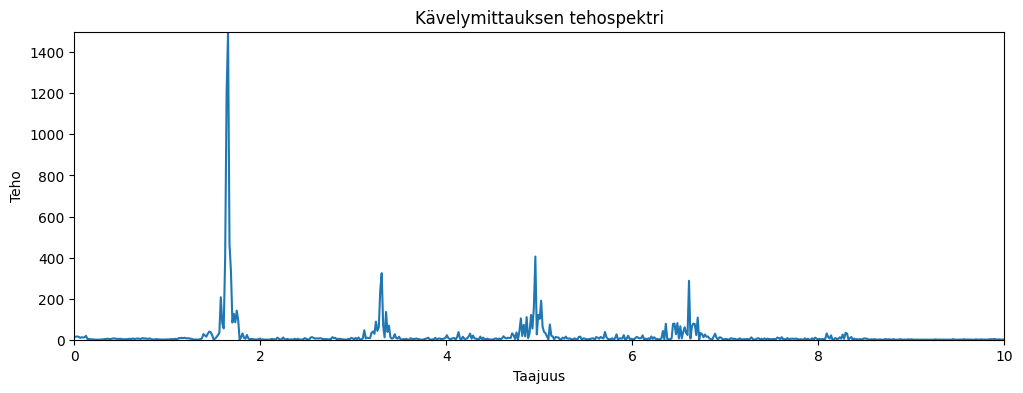

Dominoiva askeltaajuus [1.65215506] Hz
Askelaika [0.60527007] s
Askelmäärä [106.]


np.float64(126.21841189678948)

In [ ]:
# Tehtävä 15
# Käytä tehtävän 11 tasavauhtista kävelymittausta.

# a) Laske valitun kiihtyvyyskomponentin Fourier-muunnos ja tehospektri.
# b) Tunnista hallitseva taajuus ja arvioi, vastaako se askelta vai askelparia.
# c) Arvioi askelmäärä taajuuden ja mittausajan avulla.
# d) Vertaa tulosta suodatusmenetelmään ja itse laskemaasi askelmäärään.
# e) Kirjaa, millaisilla oletuksilla Fourier-menetelmä toimii tässä mittauksessa.

df = pd.read_csv('./Data/askeldata.csv')
# plt.figure(figsize=(26,8))
# plt.plot(df['Time (s)'],df['Linear Acceleration y (m/s^2)'],label = 'y')
# plt.grid()
# plt.legend()
# plt.show()

#signaali
s = df['Linear Acceleration y (m/s^2)']
#aika
t = df['Time (s)']

#Fourier-muunnos ja tehospektri
N = len(s)
time_interval = (np.max(t) - np.min(t)) #Koko havaintojakson pituus
dt =time_interval/(N-1) #Oletetaan vakioksi
fourier = np.fft.fft(s,N)
psd = fourier*np.conj(fourier)/N
freq = np.fft.fftfreq(N,dt)
L = np.arange(1,np.floor(N/2),dtype = 'int')

plt.figure(figsize=(12,4))
plt.plot(freq[L],psd[L].real)
plt.axis([0,10,0,1500])
plt.xlabel('Taajuus')
plt.ylabel('Teho')
plt.title('Kävelymittauksen tehospektri')
plt.show()

f_max = freq[L][psd[L].real == np.max(psd[L].real)] #Taajuus, jolla teho kaikkein suurin (näkyy myös kuvaajassa), eli askelluksen dominoiva taajuus. 
T = 1/f_max #Askeleeseen kuluva aika
askelet = time_interval*f_max
print('Dominoiva askeltaajuus', f_max , 'Hz')
print('Askelaika', T, 's')
print('Askelmäärä', np.round(askelet))

#vrt. huippujen ylitykset 105 askelta ja nollan ylitykset 103 askelta. 

#Tällä menetelmällä oletamme, että kävely alkaa tarkasti mittauksen alussa ja päättyy sen lopussa. Todellisuudessa alussa ja lopussa ollaan usein paikallaan --> liian suuri arvio.
#Tässä tapauksessa myös oletamme, että askeltaajuus pysyy samana koko mittauksen ajan.
#Vaihtelu voidaan huomioida jakamalla havaintodata osiin ja laskemalla taajuus jokaisessa osassa erikseen.

#Näytteenottotaajuus on 126Hz, mutta askeltaajuuden havainnointiin riittäisi helposti 5 Hz. 

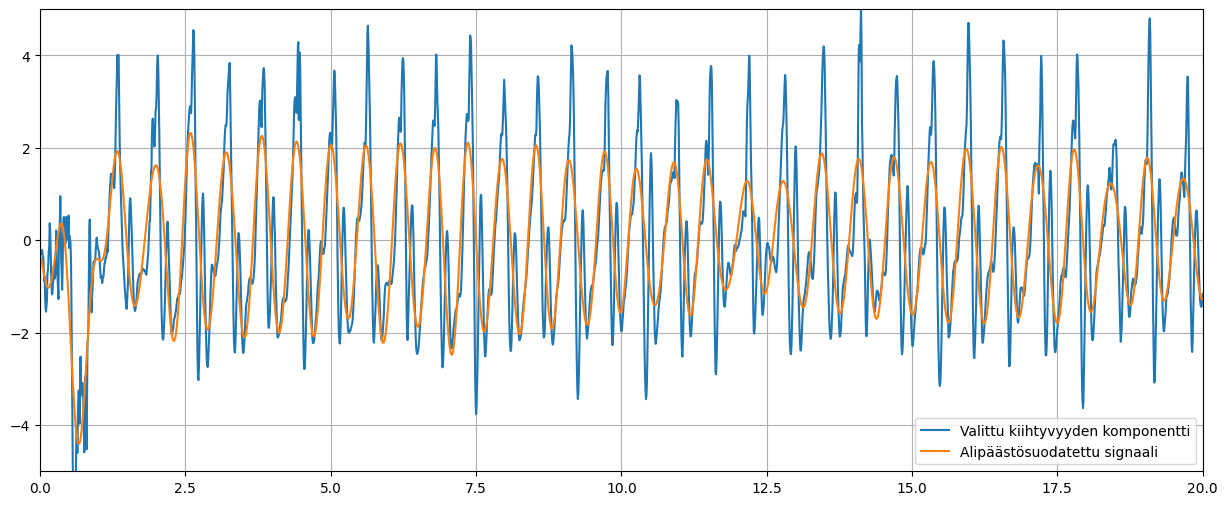

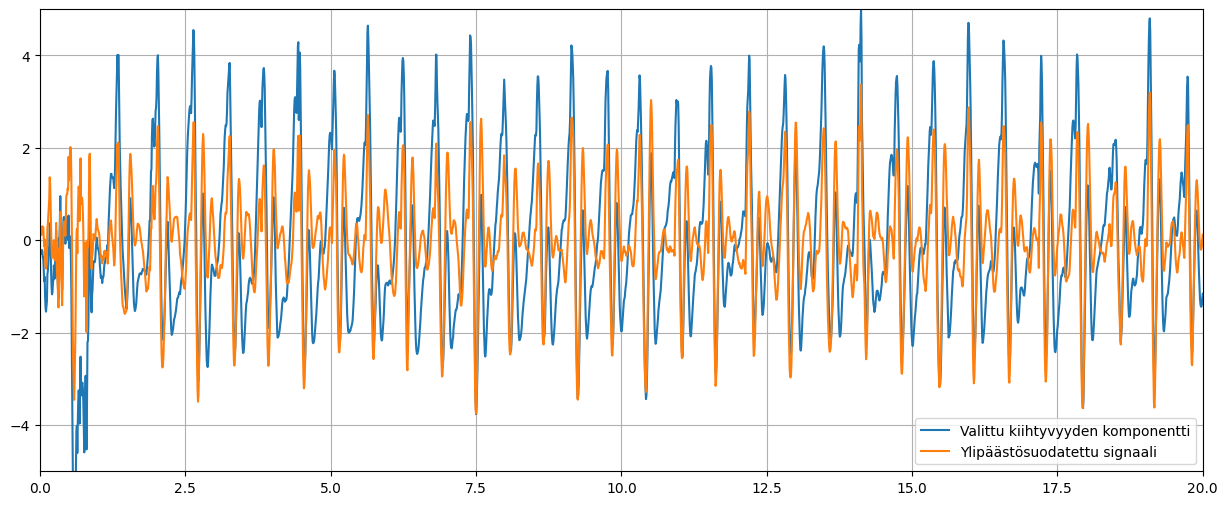

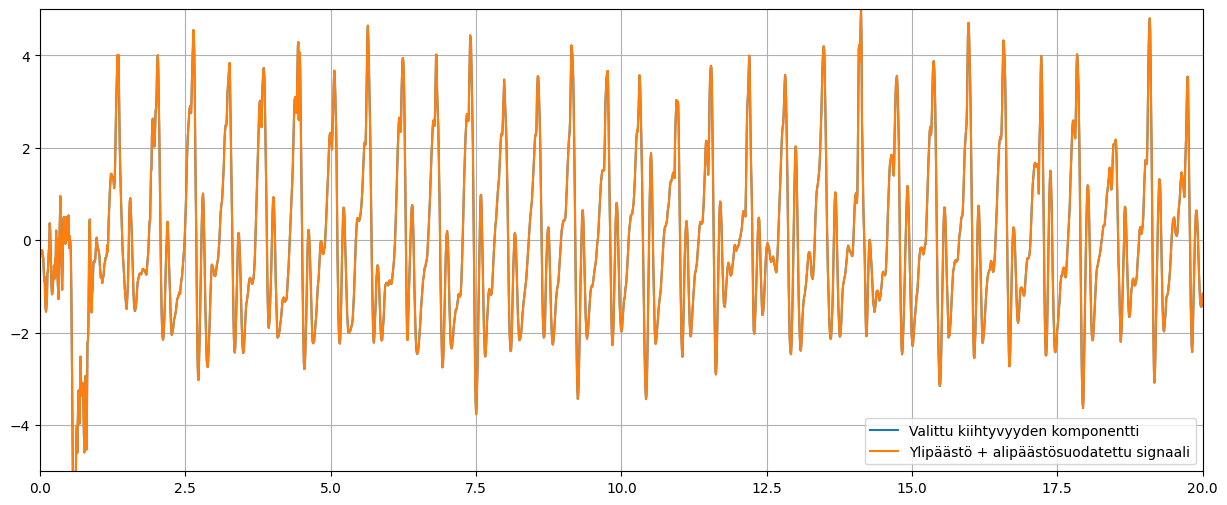

In [84]:
# Tehtävä 16
# Kirjoita Fourier-muunnokseen perustuvat yli- ja alipäästösuodattimet. Anna funktioille parametreina signaali, näytteenottoväli ja rajataajuus.

# a) Testaa suodattimia tunnetulla summasignaalilla.
# b) Testaa niitä kävelymittaukseen.
# c) Vertaa tuloksia tehtävässä 11 käyttämääsi suodatukseen.

def alipaasto(signal,dt,cutoff):
    N = len(signal)
    freq = np.fft.fftfreq(N,dt)
    fourier = np.fft.fft(signal,N)
    fourier[np.abs(freq) > cutoff] = 0 #cutoff-taajuutta suurempaa vastaavat arvot asetetaan nollaan
    signal_cleaned = np.fft.ifft(fourier) #Palautetaan signaali käänteissmuunnoksella
    return signal_cleaned

def ylipaasto(signal,dt,cutoff):
    N = len(signal)
    freq = np.fft.fftfreq(N,dt)
    fourier = np.fft.fft(signal,N)
    fourier[np.abs(freq) < cutoff] = 0 #cutoff-taajuutta suurempaa vastaavat arvot asetetaan nollaan
    signal_cleaned = np.fft.ifft(fourier) #Palautetaan signaali käänteissmuunnoksella
    return signal_cleaned


df = pd.read_csv('./Data/askeldata.csv')
signal = df['Linear Acceleration y (m/s^2)']
t = df['Time (s)']
N = len(t)
time_interval = (np.max(t) - np.min(t)) #Koko havaintojakson pituus
dt =time_interval/(N-1) #Oletetaan vakioksi
cutoff = 1/0.4 #Cutt-off taajuus

signal_cleaned = alipaasto(signal,dt,cutoff)
signal_cleaned2 = ylipaasto(signal,dt,cutoff)

plt.figure(figsize=(15,6))
plt.plot(t,signal,label = 'Valittu kiihtyvyyden komponentti')
plt.plot(t,signal_cleaned.real,label = 'Alipäästösuodatettu signaali')
plt.grid()
plt.axis([0,20,-5,5])
plt.legend()
plt.show()

plt.figure(figsize=(15,6))
plt.plot(t,signal,label = 'Valittu kiihtyvyyden komponentti')
plt.plot(t,signal_cleaned2.real,label = 'Ylipäästösuodatettu signaali')
plt.grid()
plt.axis([0,20,-5,5])
plt.legend()
plt.show()

plt.figure(figsize=(15,6))
plt.plot(t,signal,label = 'Valittu kiihtyvyyden komponentti')
plt.plot(t,signal_cleaned.real+signal_cleaned2.real,label = 'Ylipäästö + alipäästösuodatettu signaali')
plt.grid()
plt.axis([0,20,-5,5])
plt.legend()
plt.show()
